# **Color Spaces and Channel Manipulation**
**Objective:** Understand how color images are stored, and practise working with BGR, RGB, HSV and LAB color spaces using OpenCV and NumPy.

**Tools:** Python, OpenCV, NumPy, Google Colab

In [ ]:
# Setup: install and import required libraries

!pip install -q opencv-python
import cv2, numpy as np
from google.colab.patches import cv2_imshow
from google.colab import files

In [ ]:
## Load image in BGR and validate it

# Uploading image

uploaded = files.upload()
fname = list(uploaded.keys())[0]

# Reading image in BGR (OpenCV default)
img_bgr = cv2.imread(fname)
assert img_bgr is not None, "Image failed to load. Please upload a colored photo."
assert img_bgr.ndim == 3 and img_bgr.shape[2] == 3, "Image failed to load. Please upload a colored photo.(3 channels)"

h, w = img_bgr.shape[:2]

print(f"Loaded: {fname}, | Shape (H, W, C): {img_bgr.shape}, | Dtype: {img_bgr.dtype}")

Saving image.png to image (1).png
Loaded: image (1).png, | Shape (H, W, C): (676, 1200, 3), | Dtype: uint8


In [ ]:
# Read BGR values of a single pixel

y, x = 80, 120
b, g, r = img_bgr[y, x]

print(f"Pixel at (y=80, x=120) -> B: , G: , R: {b}, {g}, {r}")

Pixel at (y=80, x=120) -> B: , G: , R: 37, 34, 26


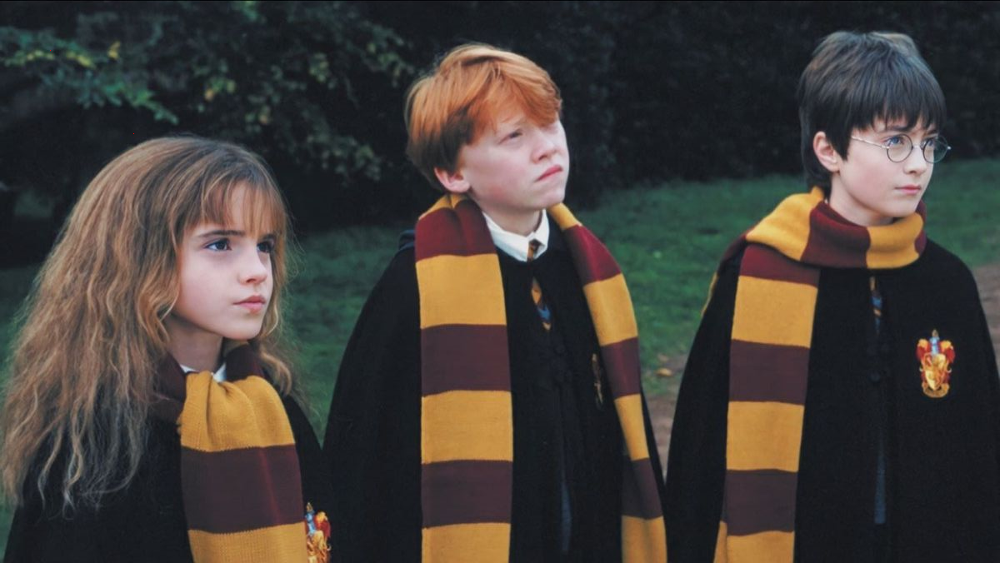

In [ ]:
# Modify a single pixel (set to red)

img2 = img_bgr.copy()

img2[60, 60] = [0, 0, 255]

cv2_imshow(img2)

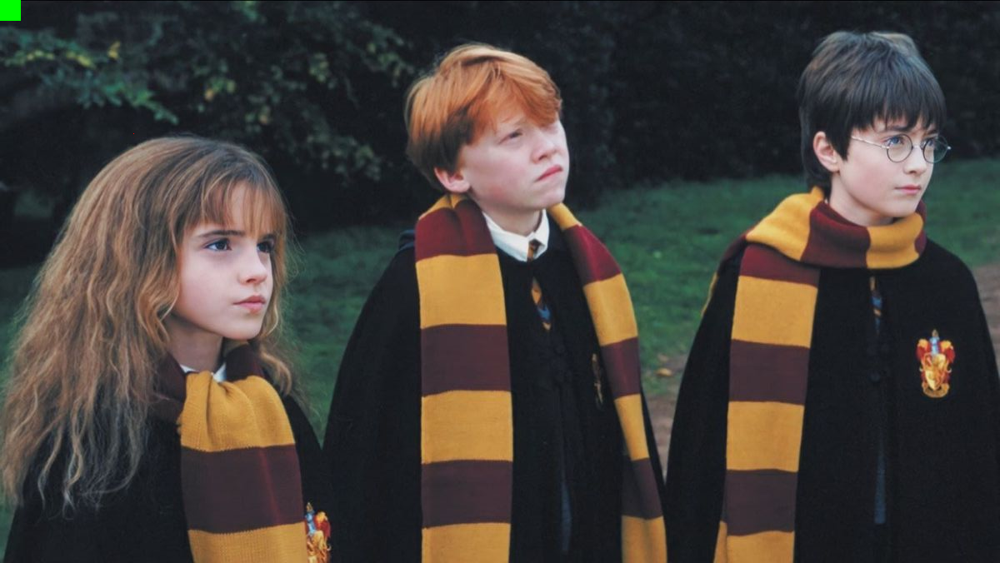

In [ ]:
# Modify a region (paint a 25x25 green square)

img3 = img_bgr.copy()
img3[0:25, 0:25] = [0, 255, 0]

cv2_imshow(img3)

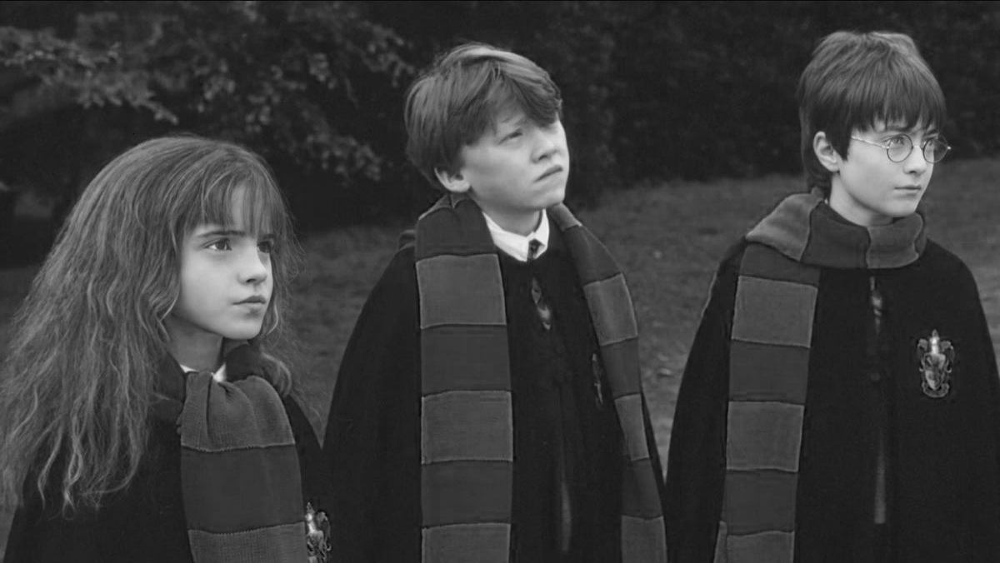

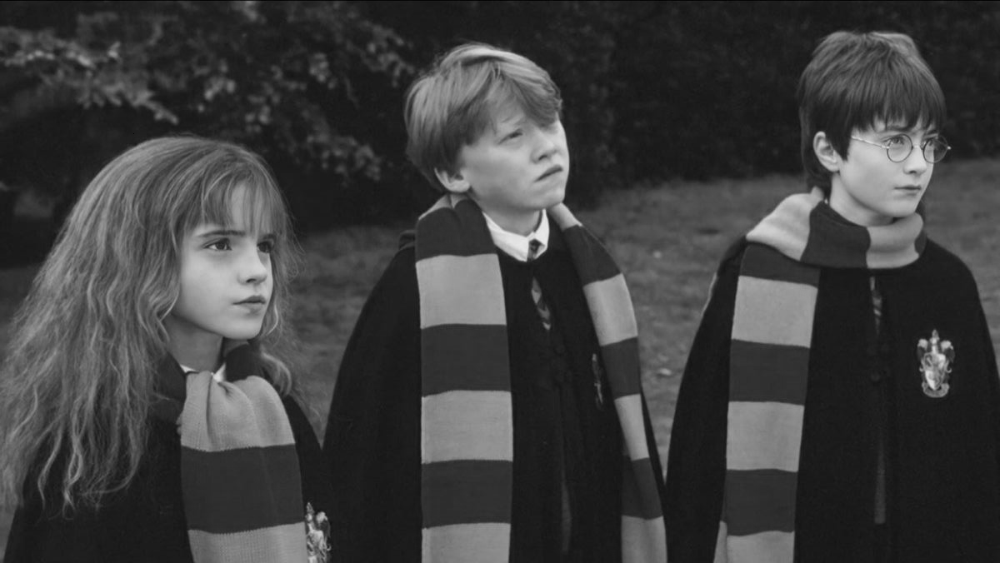

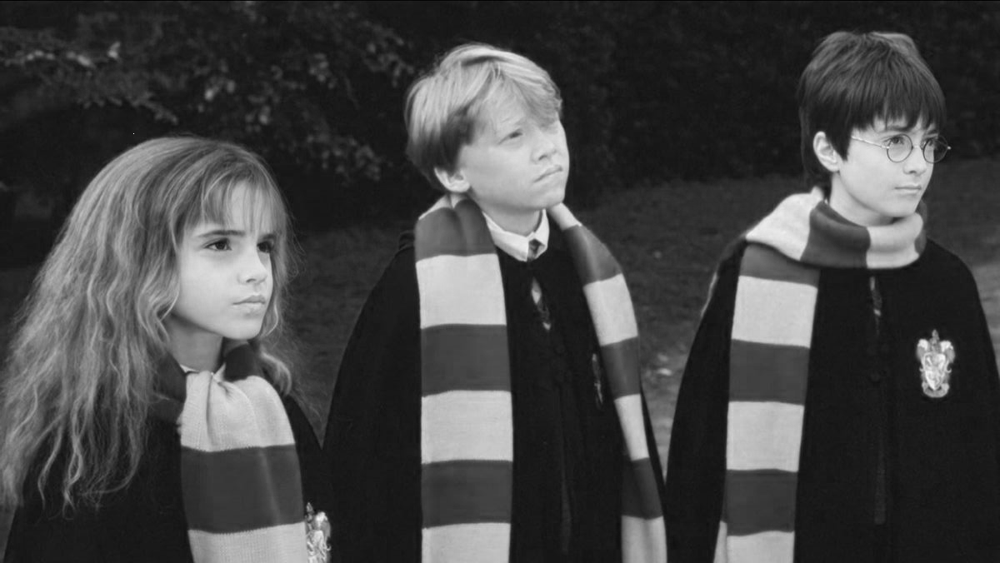

In [ ]:
# Split image into B, G, R channels

b, g, r = cv2.split(img_bgr)

cv2_imshow(b) # appears as gray: brighter means more blue
cv2_imshow(g) # green intesifies
cv2_imshow(r) # red intensifies

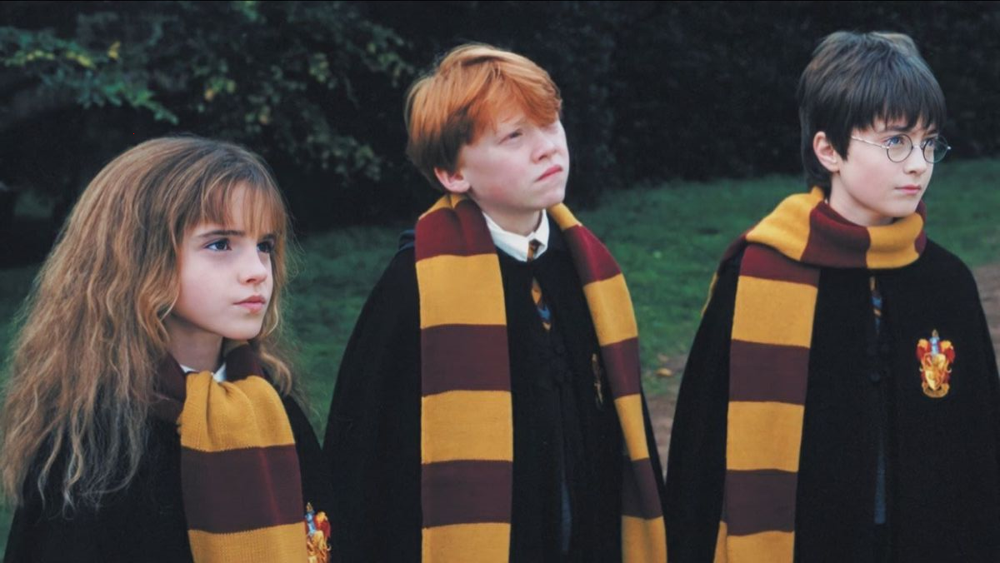

In [ ]:
# Merge channels back into a color image

remerged = cv2.merge([b, g, r])
cv2_imshow(remerged)

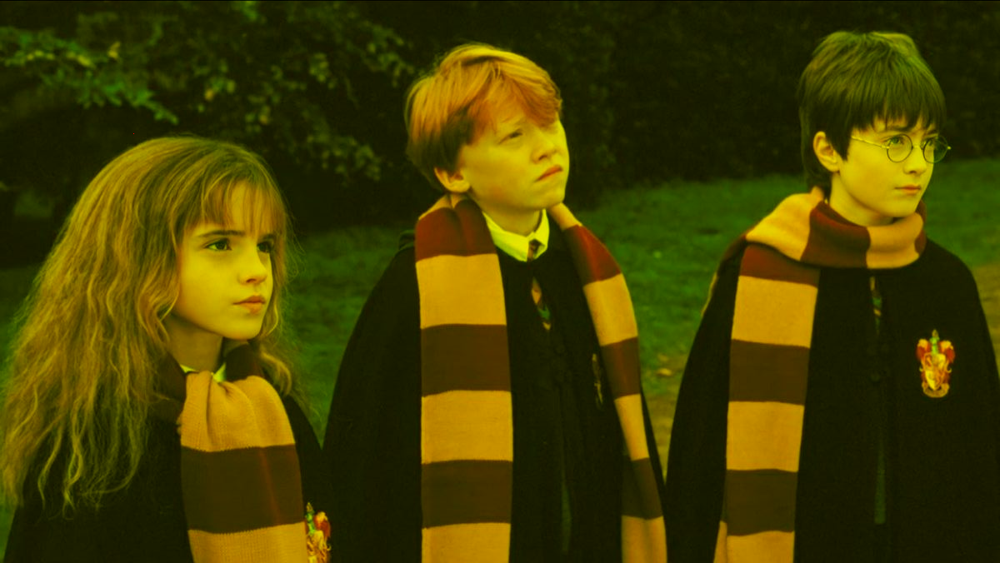

In [ ]:
# Remove the blue channel

img4 = img_bgr.copy()
img4[:, :, 0] = 0

cv2_imshow(img4)

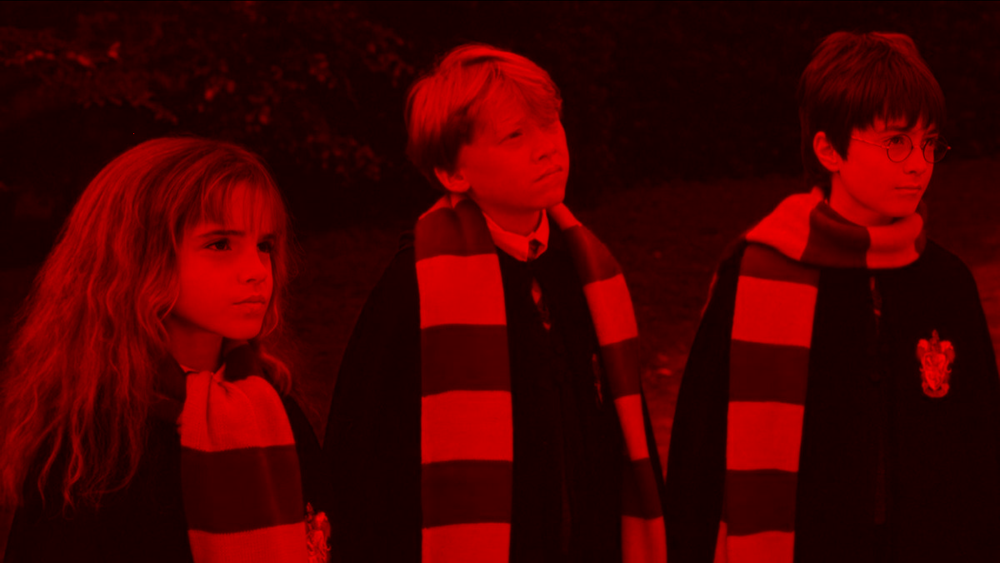

In [ ]:
# Isolate the red channel

zeros = np.zeros_like(b)
red_only = cv2.merge([zeros, zeros, r])
cv2_imshow(red_only)

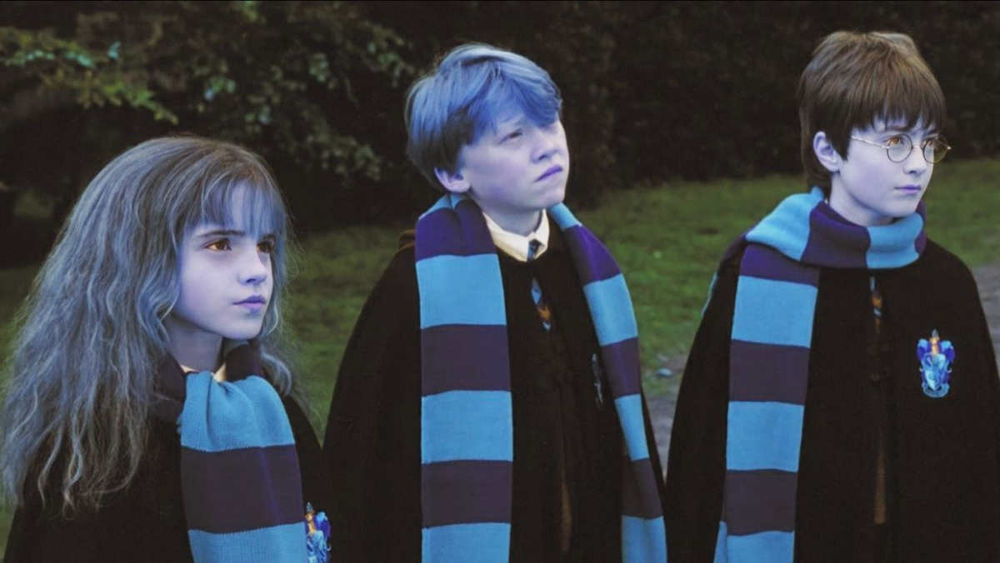

In [ ]:
# Convert BGR to RGB

img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
cv2_imshow(img_rgb)

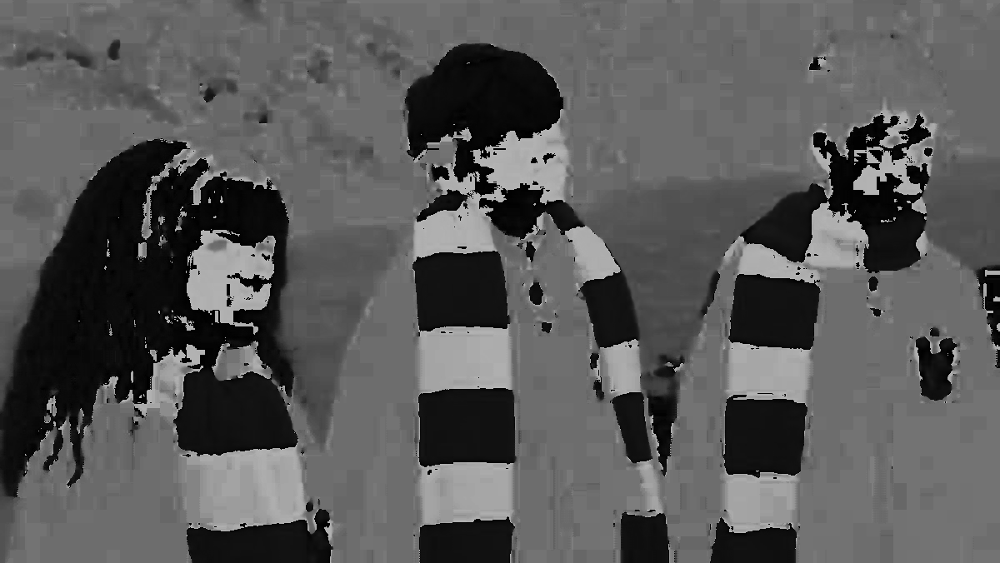

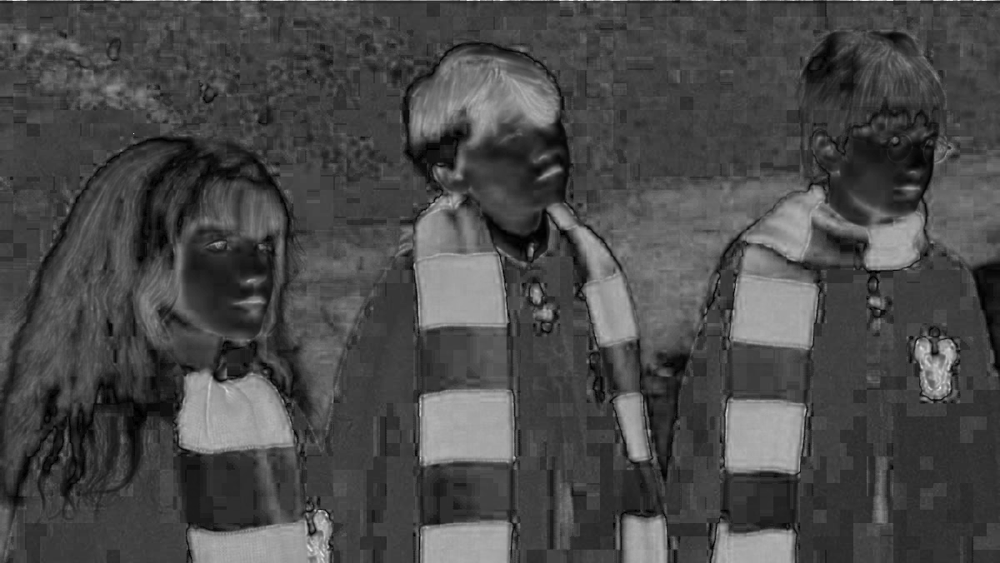

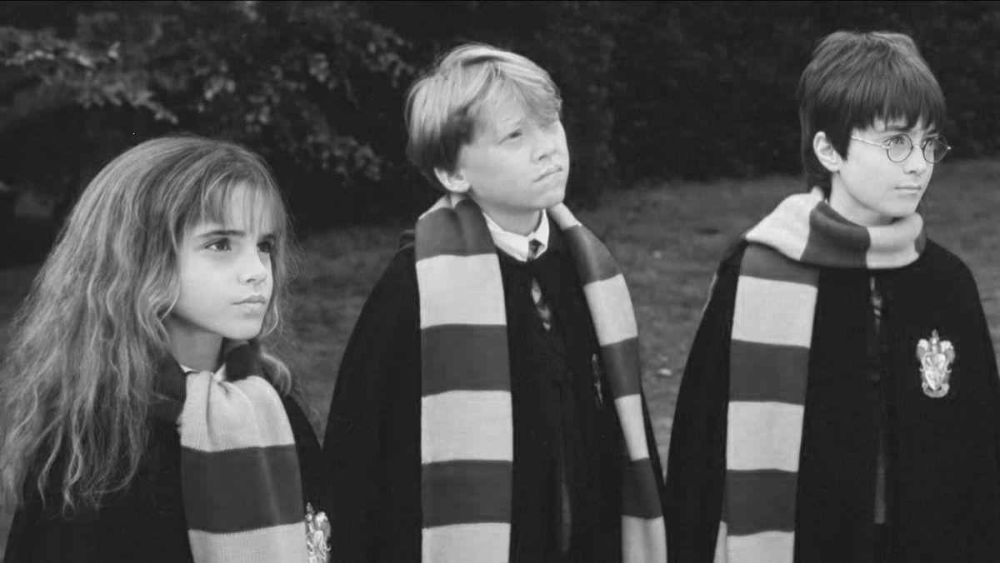

Hue range (OpenCV):  0 to 179 (0..179)


In [ ]:
# Convert BGR to HSV and split channels

img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
H, S, V = cv2.split(img_hsv)

cv2_imshow(H)
cv2_imshow(S)
cv2_imshow(V)
print("Hue range (OpenCV): ", int(H.min()),"to", int(H.max()), "(0..179)")

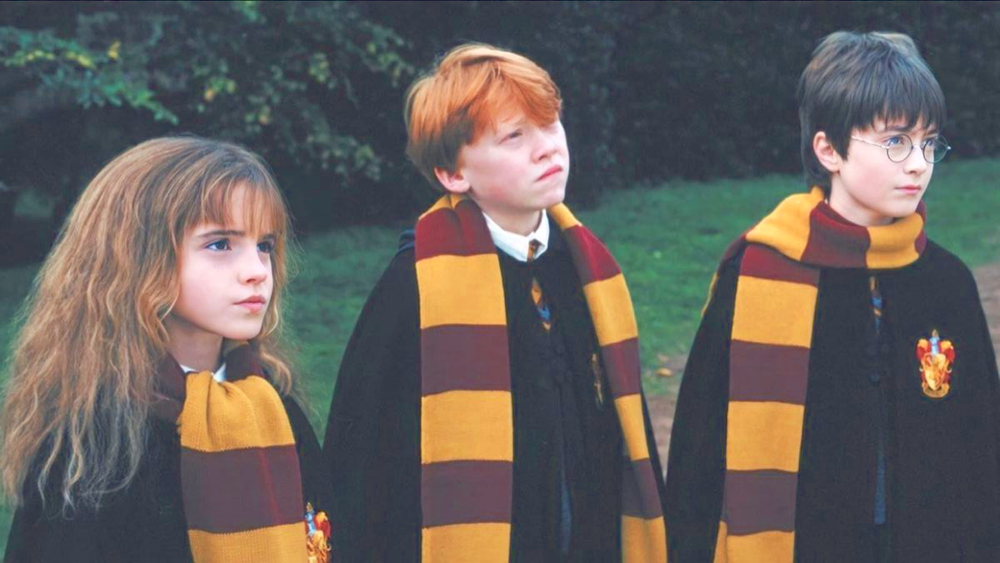

In [ ]:
# Increase brightness (V channel)

bright_hsv = img_hsv.copy()
bright_hsv[:,:,2] = cv2.add(bright_hsv[:,:,2], 40)
bright_bgr = cv2.cvtColor(bright_hsv, cv2.COLOR_HSV2BGR)
cv2_imshow(bright_bgr)

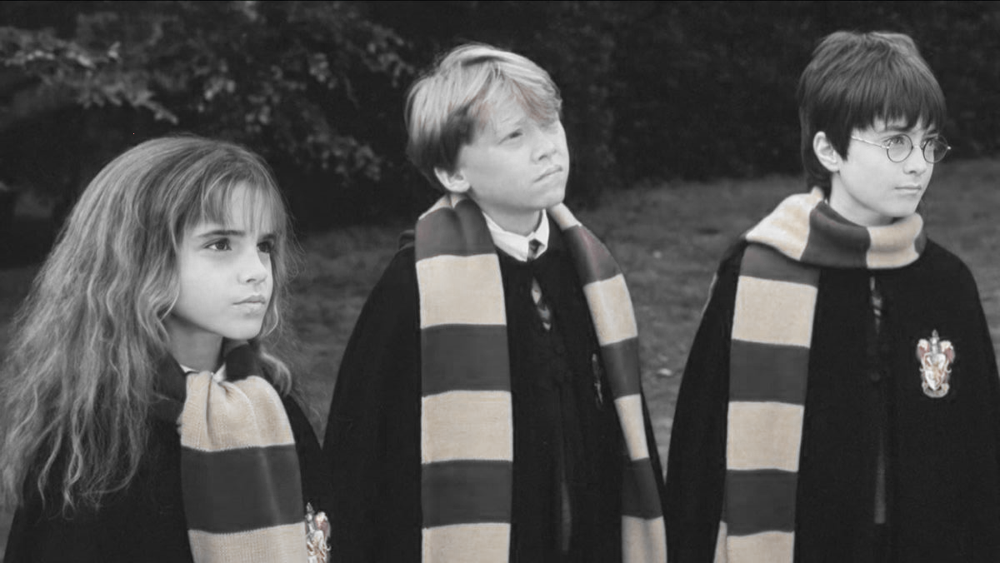

In [ ]:
# Decrease saturation (S channel)

softer_hsv = img_hsv.copy()
softer_hsv[:,:,1] = cv2.subtract(softer_hsv[:,:,1], 140)
softer_bgr = cv2.cvtColor(softer_hsv, cv2.COLOR_HSV2BGR)
cv2_imshow(softer_bgr)

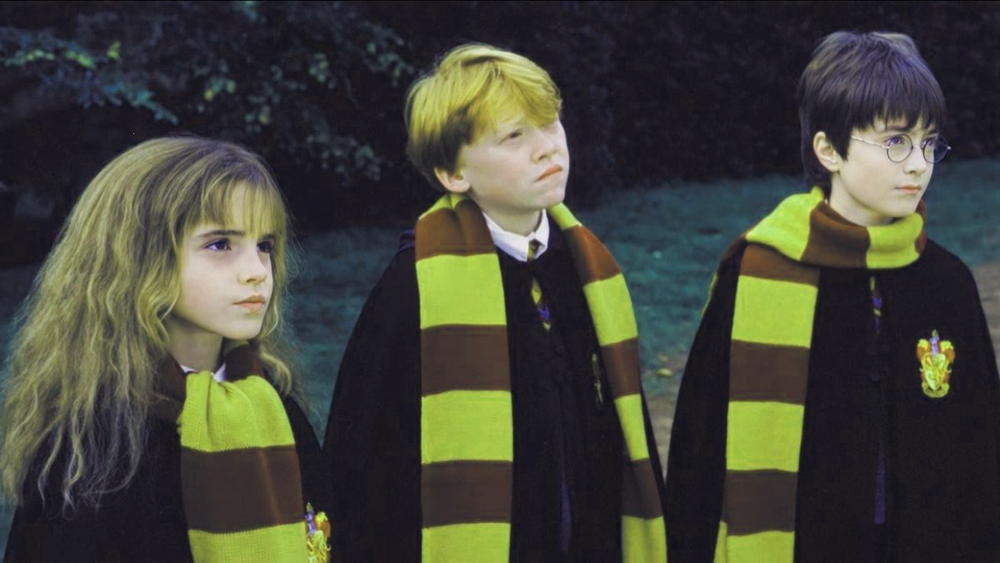

In [ ]:
# Shift hue (H channel) with wrap-around

shift_hsv = img_hsv.copy()
shift_amount = 20
shift_hsv[:,:,0] = ((shift_hsv[:,:,0].astype(np.int16) + shift_amount) % 180).astype(np.uint8)
shift_bgr = cv2.cvtColor(shift_hsv, cv2.COLOR_HSV2BGR)
cv2_imshow(shift_bgr)

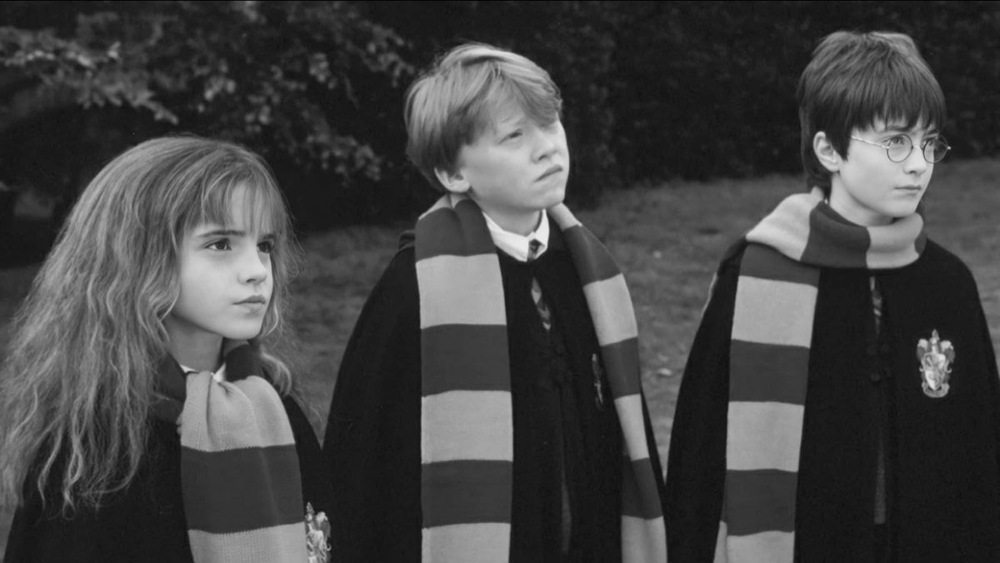

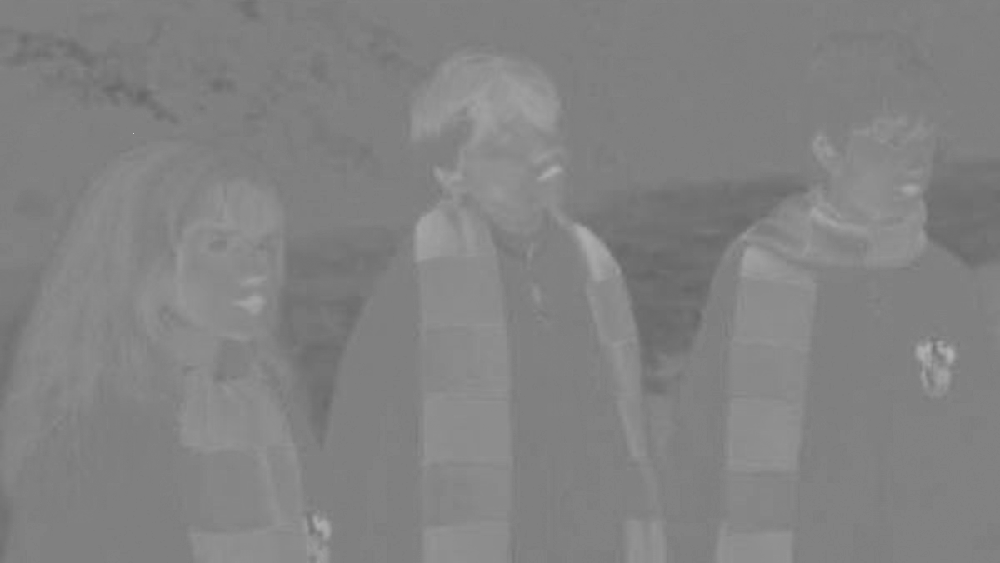

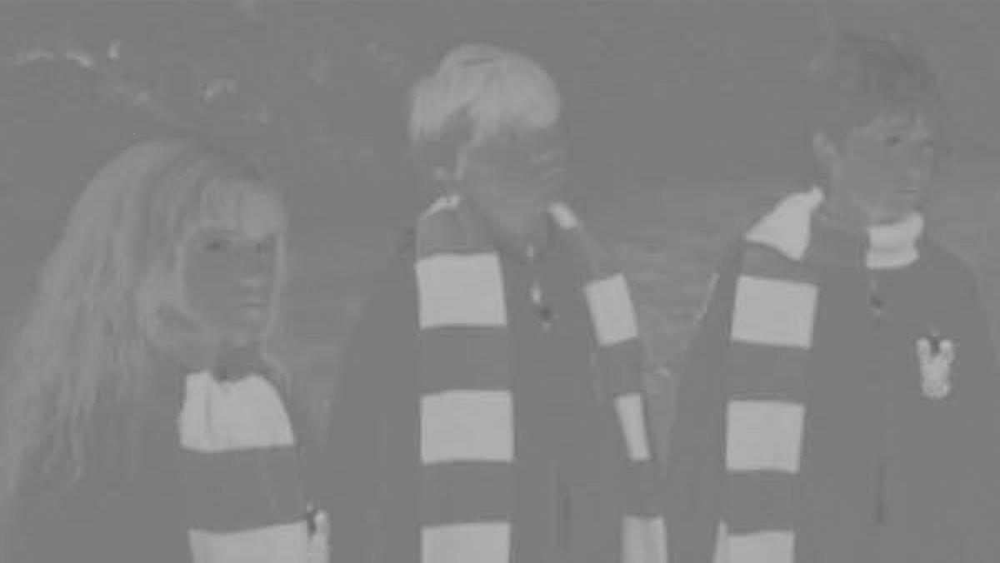

In [ ]:
# Convert BGR to LAB and split channels

img_lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
L, A, B = cv2.split(img_lab)

cv2_imshow(L)
cv2_imshow(A)
cv2_imshow(B)